In [3]:
import pandas as pd
import numpy as np

In [4]:

nav = pd.read_csv(
    r"C:\Users\sarth\Downloads\capstone mf analysis project\data\processed\nav_history_cleaned.csv"
)

nav.head()

,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639


In [5]:
nav.columns

Index(['amfi_code', 'date', 'nav'], dtype='object')

In [6]:
nav['date'] = pd.to_datetime(nav['date'])

nav = nav.sort_values(
    ['amfi_code', 'date']
).reset_index(drop=True)

nav.head()

,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639


In [7]:
nav['daily_return'] = (
    nav.groupby('amfi_code')['nav']
       .pct_change()
)

nav.head()

,amfi_code,date,nav,daily_return
0,100016,2022-01-03,520.4608,NaN
1,100016,2022-01-04,515.0971,-0.010306
2,100016,2022-01-05,521.7239,0.012865
3,100016,2022-01-06,515.7880,-0.011377
4,100016,2022-01-07,515.1639,-0.001210


In [8]:
var_cvar_results = []

for amfi_code, group in nav.groupby('amfi_code'):
    returns = group['daily_return'].dropna()

    var_95 = returns.quantile(0.05)
    cvar_95 = returns[returns < var_95].mean()

    var_cvar_results.append({
        'amfi_code': amfi_code,
        'VaR_95': var_95,
        'CVaR_95': cvar_95
    })

var_cvar = pd.DataFrame(var_cvar_results)

var_cvar.head()

,amfi_code,VaR_95,CVaR_95
0,100016,-0.014364,-0.018060
1,100025,-0.003793,-0.004994
2,100033,-0.019034,-0.023456
3,101206,-0.013282,-0.017439
4,101207,-0.026021,-0.032459


In [9]:

len(var_cvar)

40

In [10]:
var_cvar.to_csv(
    r"C:\Users\sarth\Downloads\capstone mf analysis project\Advanced_Analytics\var_cvar_report.csv",
    index=False
)

OSError: Cannot save file into a non-existent directory: 'C:\Users\sarth\Downloads\capstone mf analysis project\Advanced_Analytics'

In [11]:
import os

os.listdir(r"C:\Users\sarth\Downloads\capstone mf analysis project")

['.git',
 '.gitignore',
 '.ipynb_checkpoints',
 'alpha_beta.csv',
 'benchmark_comparison.png',
 'dashboard',
 'data',
 'data_dictionary.md',
 'data_ingestion.py',
 'data_quality_check.py',
 'Day1_Data_Ingestion.ipynb',
 'fund_master_exploration.py',
 'fund_scorecard.csv',
 'live_nav_fetch.py',
 'notebooks',
 'reports',
 'requirements.txt',
 'sql']

In [13]:
var_cvar.to_csv(
    r"C:\Users\sarth\Downloads\capstone mf analysis project\notebooks\var_cvar_report.csv",
    index=False
)

In [14]:
var_cvar.head(10)

,amfi_code,VaR_95,CVaR_95
0,100016,-0.014364,-0.018060
1,100025,-0.003793,-0.004994
2,100033,-0.019034,-0.023456
3,101206,-0.013282,-0.017439
4,101207,-0.026021,-0.032459
5,101208,-0.000269,-0.000422
6,102885,-0.012613,-0.015490
7,102886,-0.019220,-0.023251
8,102887,-0.015232,-0.019411
9,118632,-0.013954,-0.017619


In [15]:
key_funds = [118632, 119092, 119551, 120503, 120841]

nav[nav['amfi_code'].isin(key_funds)]['amfi_code'].unique()

array([118632, 119092, 119551, 120503, 120841])

In [16]:
rolling_sharpe = nav[nav['amfi_code'].isin(key_funds)].copy()

rolling_sharpe['rolling_sharpe_90'] = (
    rolling_sharpe.groupby('amfi_code')['daily_return']
    .transform(lambda x: (
        x.rolling(90).mean() /
        x.rolling(90).std()
    ) * np.sqrt(252)
)

rolling_sharpe[['amfi_code', 'date', 'rolling_sharpe_90']].head(100)

SyntaxError: '(' was never closed (1522954671.py, line 3)

In [17]:
rolling_sharpe = nav[nav['amfi_code'].isin(key_funds)].copy()

rolling_sharpe['rolling_sharpe_90'] = (
    rolling_sharpe.groupby('amfi_code')['daily_return']
    .transform(
        lambda x: (
            x.rolling(90).mean() /
            x.rolling(90).std()
        ) * np.sqrt(252)
    )
)

rolling_sharpe[['amfi_code', 'date', 'rolling_sharpe_90']].head(100)

,amfi_code,date,rolling_sharpe_90
10350,118632,2022-01-03,NaN
10351,118632,2022-01-04,NaN
10352,118632,2022-01-05,NaN
10353,118632,2022-01-06,NaN
10354,118632,2022-01-07,NaN
...,...,...,...
10445,118632,2022-05-16,4.572137
10446,118632,2022-05-17,4.632987
10447,118632,2022-05-18,4.757113
10448,118632,2022-05-19,4.786752


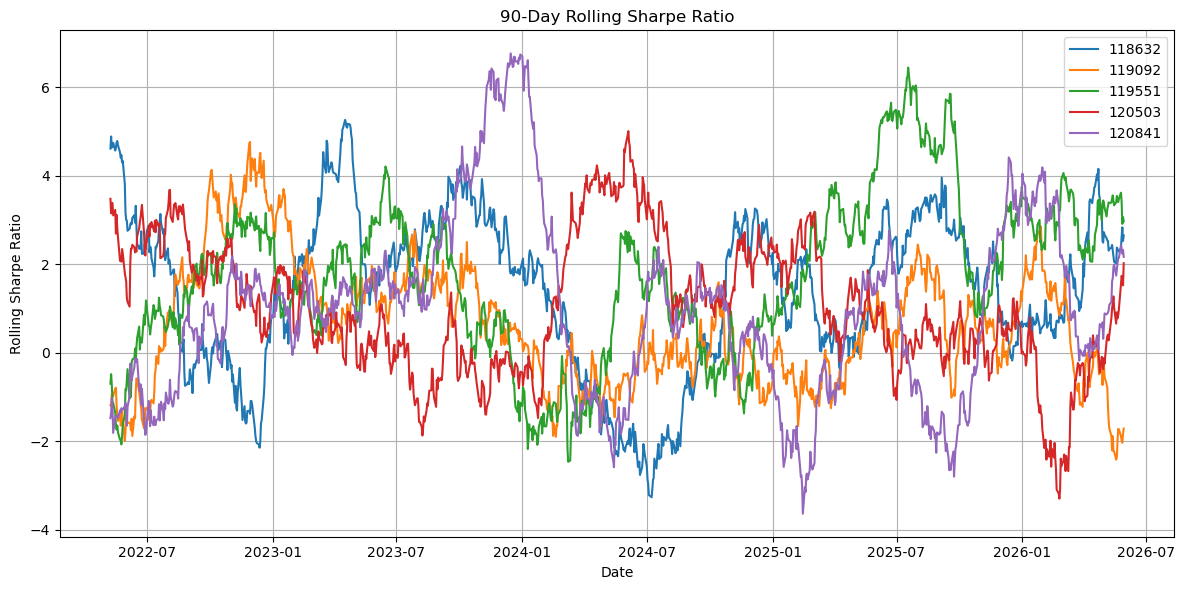

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for fund in key_funds:
    fund_data = rolling_sharpe[
        rolling_sharpe['amfi_code'] == fund
    ]

    plt.plot(
        fund_data['date'],
        fund_data['rolling_sharpe_90'],
        label=str(fund)
    )

plt.title('90-Day Rolling Sharpe Ratio')
plt.xlabel('Date')
plt.ylabel('Rolling Sharpe Ratio')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [20]:
plt.savefig(
    r"C:\Users\sarth\Downloads\capstone mf analysis project\notebooks\rolling_sharpe_chart.png",
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

In [21]:
transactions = pd.read_csv(
    r"C:\Users\sarth\Downloads\capstone mf analysis project\data\processed\investor_transactions_cleaned.csv"
)

transactions.head()

,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status
0,INV003054,2024-01-01,119092,SIP,1834,Telangana,Hyderabad,T30,56+,Female,77.1,UPI,Verified
1,INV002952,2024-01-01,148567,Redemption,392882,Punjab,Amritsar,B30,18-25,Male,7.1,Cheque,Verified
2,INV003420,2024-01-01,118636,SIP,912,Haryana,Faridabad,B30,36-45,Male,47.2,Mandate,Verified
3,INV003436,2024-01-01,118634,SIP,1102,Maharashtra,Mumbai,T30,36-45,Female,54.4,Cheque,Pending
4,INV004691,2024-01-01,119094,Lumpsum,8682,Delhi,Noida,T30,26-35,Male,14.5,Net Banking,Pending


In [22]:
transactions.columns

Index(['investor_id', 'transaction_date', 'amfi_code', 'transaction_type',
       'amount_inr', 'state', 'city', 'city_tier', 'age_group', 'gender',
       'annual_income_lakh', 'payment_mode', 'kyc_status'],
      dtype='object')

In [23]:
transactions['transaction_date'] = pd.to_datetime(
    transactions['transaction_date']
)

first_transaction = (
    transactions.groupby('investor_id')['transaction_date']
    .min()
    .reset_index()
)

first_transaction['cohort_year'] = (
    first_transaction['transaction_date'].dt.year
)

first_transaction.head()

,investor_id,transaction_date,cohort_year
0,INV000001,2024-11-04,2024
1,INV000002,2024-03-29,2024
2,INV000003,2024-07-16,2024
3,INV000004,2024-03-16,2024
4,INV000005,2024-04-27,2024


In [24]:
transactions = transactions.merge(
    first_transaction[['investor_id', 'cohort_year']],
    on='investor_id',
    how='left'
)

transactions.head()

,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status,cohort_year
0,INV003054,2024-01-01,119092,SIP,1834,Telangana,Hyderabad,T30,56+,Female,77.1,UPI,Verified,2024
1,INV002952,2024-01-01,148567,Redemption,392882,Punjab,Amritsar,B30,18-25,Male,7.1,Cheque,Verified,2024
2,INV003420,2024-01-01,118636,SIP,912,Haryana,Faridabad,B30,36-45,Male,47.2,Mandate,Verified,2024
3,INV003436,2024-01-01,118634,SIP,1102,Maharashtra,Mumbai,T30,36-45,Female,54.4,Cheque,Pending,2024
4,INV004691,2024-01-01,119094,Lumpsum,8682,Delhi,Noida,T30,26-35,Male,14.5,Net Banking,Pending,2024


In [25]:
cohort_analysis = (
    transactions.groupby('cohort_year')
    .agg(
        avg_sip_amount=(
            'amount_inr',
            lambda x: x[
                transactions.loc[x.index, 'transaction_type'].str.lower() == 'sip'
            ].mean()
        ),
        total_invested=('amount_inr', 'sum')
    )
    .reset_index()
)

cohort_analysis

,cohort_year,avg_sip_amount,total_invested
0,2024,10996.885825,3491125187
1,2025,13505.209581,30455243


In [26]:
top_fund_by_cohort = (
    transactions.groupby(['cohort_year', 'amfi_code'])
    .size()
    .reset_index(name='transaction_count')
    .sort_values(
        ['cohort_year', 'transaction_count'],
        ascending=[True, False]
    )
    .drop_duplicates('cohort_year')
)

top_fund_by_cohort

,cohort_year,amfi_code,transaction_count
35,2024,148568,874
62,2025,119599,12


In [27]:
cohort_analysis = cohort_analysis.merge(
    top_fund_by_cohort[['cohort_year', 'amfi_code']],
    on='cohort_year',
    how='left'
)

cohort_analysis

,cohort_year,avg_sip_amount,total_invested,amfi_code
0,2024,10996.885825,3491125187,148568
1,2025,13505.209581,30455243,119599


In [28]:
sip_transactions = transactions[
    transactions['transaction_type'].str.lower() == 'sip'
].copy()

sip_transactions.head()

,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status,cohort_year
0,INV003054,2024-01-01,119092,SIP,1834,Telangana,Hyderabad,T30,56+,Female,77.1,UPI,Verified,2024
2,INV003420,2024-01-01,118636,SIP,912,Haryana,Faridabad,B30,36-45,Male,47.2,Mandate,Verified,2024
3,INV003436,2024-01-01,118634,SIP,1102,Maharashtra,Mumbai,T30,36-45,Female,54.4,Cheque,Pending,2024
5,INV001497,2024-01-01,101208,SIP,3295,Maharashtra,Mumbai,T30,36-45,Male,56.8,Mandate,Verified,2024
6,INV000786,2024-01-01,101208,SIP,15047,Madhya Pradesh,Bhopal,B30,26-35,Male,17.9,Mandate,Verified,2024


In [33]:
sip_transactions = sip_transactions.sort_values(
    ['investor_id', 'transaction_date']
)

sip_transactions['gap_days'] = (
    sip_transactions
    .groupby('investor_id')['transaction_date']
    .diff()
    .dt.days
)

In [35]:
sip_6plus = sip_transactions.groupby('investor_id').filter(
    lambda x: len(x) >= 6
)

In [36]:
sip_continuity = (
    sip_6plus.groupby('investor_id')['gap_days']
    .mean()
    .reset_index(name='avg_gap_days')
)

sip_continuity['status'] = np.where(
    sip_continuity['avg_gap_days'] > 35,
    'at-risk',
    'regular'
)

sip_continuity

,investor_id,avg_gap_days,status
0,INV000004,85.400000,at-risk
1,INV000008,70.400000,at-risk
2,INV000010,64.800000,at-risk
3,INV000011,40.166667,at-risk
4,INV000012,57.000000,at-risk
...,...,...,...
1357,INV004984,75.333333,at-risk
1358,INV004986,81.333333,at-risk
1359,INV004992,81.500000,at-risk
1360,INV004996,46.333333,at-risk


In [39]:
portfolio = pd.read_csv(
    r"C:\Users\sarth\Downloads\capstone mf analysis project\data\raw\1788499982117-e3d6ab98-09_portfolio_holdings.csv"
)

In [40]:
portfolio.columns

Index(['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct',
       'market_value_cr', 'current_price_inr', 'portfolio_date'],
      dtype='object')

In [41]:
portfolio['weight'] = portfolio['weight_pct'] / 100

hhi = (
    portfolio.groupby('amfi_code')['weight']
    .apply(lambda x: (x ** 2).sum())
    .reset_index(name='HHI')
)

hhi

,amfi_code,HHI
0,100016,0.139534
1,100033,0.147592
2,101206,0.129332
3,101207,0.200700
4,102885,0.174709
5,102886,0.114693
6,102887,0.129805
7,118632,0.168298
8,118633,0.121461
9,118634,0.108358


In [42]:
fund_master = pd.read_csv(
    r"C:\Users\sarth\Downloads\capstone mf analysis project\data\raw\1788499983024-b042c300-01_fund_master.csv"
)

equity_codes = fund_master[
    fund_master['category'].str.contains('Equity', case=False, na=False)
]['amfi_code']

equity_hhi = hhi[
    hhi['amfi_code'].isin(equity_codes)
]

equity_hhi

,amfi_code,HHI
0,100016,0.139534
1,100033,0.147592
2,101206,0.129332
3,101207,0.200700
4,102885,0.174709
5,102886,0.114693
6,102887,0.129805
7,118632,0.168298
8,118633,0.121461
9,118634,0.108358


## Advanced Insights

1. Historical VaR and CVaR show the downside-risk levels of the 40 mutual fund schemes based on their daily return distributions.

2. The 90-day rolling Sharpe analysis shows how the risk-adjusted performance of the five selected funds changes over time.

3. Investor cohort analysis compares investors based on their first transaction year using average SIP amount, total invested amount, and preferred fund.

4. SIP continuity analysis identifies investors with an average SIP gap greater than 35 days as at-risk investors.

5. Sector HHI analysis shows the concentration of equity-fund portfolios based on their sector allocation weights.